# Perturbation screens

In this tutorial the donors are target genes rather than people. In a pooled CRISPR screen every cell carries a guide RNA,
several guides target the same gene, and the analysis moves between all three scales: cells to see how uniform a
knockout is, guides to check that independent guides agree, and genes to compare regulators. Drug screens have the
same structure, with compounds, doses and cells.

Here the target genes are the donors in `D`, the guides are the samples in `S`, and the cells are in `C`. We use the
ECCITE-seq screen of [Papalexi et al. (2021)](https://doi.org/10.1038/s41588-021-00778-2) in stimulated THP-1 cells.
It targets 25 candidate regulators of the immune checkpoint PD-L1 with about four guides each, includes non-targeting
controls, and measures RNA together with four surface proteins. Both readouts stay together in one MuData.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import mudata as md
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns

from donordata import DonorData, read_dd

path = Path("data/papalexi_2021.h5mu")
if not path.exists():
    path.parent.mkdir(exist_ok=True)
    urlretrieve("https://scverse-exampledata.s3.eu-west-1.amazonaws.com/pertpy/papalexi_2021.h5mu", path)
mdata = md.read_h5mu(path)
mdata

MuData object with n_obs × n_vars = 20729 × 18776
  obs:	'MULTI_ID', 'HTO_classification', 'guide_ID', 'gene_target', 'NT', 'perturbation', 'replicate', 'S.Score', 'G2M.Score', 'phase'
  4 modalities
    rna:	20729 x 18649
      obs:	'nCount_RNA', 'nFeature_RNA', 'percent.mito'
      var:	'name'
    adt:	20729 x 4
      obs:	'nCount_ADT', 'nFeature_ADT'
      var:	'name'
    hto:	20729 x 12
      obs:	'nCount_HTO', 'nFeature_HTO', 'technique'
      var:	'name'
    gdo:	20729 x 111
      obs:	'nCount_GDO'
      var:	'name'

The global `obs` holds the guide of every cell. Copies of the modality annotations in the global `obs` and `var` are
dropped. RNA counts
are normalized and log transformed, and protein counts get a centered log ratio per cell, as usual for antibody
derived tags.

In [2]:
mdata.obs = mdata.obs[[c for c in mdata.obs.columns if ":" not in c]]
mdata.var = mdata.var[[c for c in mdata.var.columns if ":" not in c]]

rna, protein = mdata.mod["rna"], mdata.mod["adt"]
sc.pp.normalize_total(rna, target_sum=1e4)
sc.pp.log1p(rna)
sc.pp.highly_variable_genes(rna, n_top_genes=2000)

log_counts = np.log1p(protein.X.toarray())
protein.X = log_counts - log_counts.mean(axis=1, keepdims=True)

mdata.obs[["guide_ID", "gene_target", "perturbation", "replicate", "phase"]].head()

,guide_ID,gene_target,perturbation,replicate,phase
l1_AAACCTGAGCCAGAAC,STAT2g2,STAT2,Perturbed,rep1,G1
l1_AAACCTGAGTGGACGT,CAV1g4,CAV1,Perturbed,rep1,G1
l1_AAACCTGCATGAGCGA,STAT1g2,STAT1,Perturbed,rep1,G1
l1_AAACCTGTCTTGTCAT,CD86g1,CD86,Perturbed,rep1,G1
l1_AAACGGGAGAACAACT,IRF7g2,IRF7,Perturbed,rep1,G1


## Genes, guides and cells

`DonorData.from_anndata` works on a MuData as well. With the target gene as the donor and the guide as the sample,
columns that are constant within every gene, here whether the gene is targeted at all, go to the gene table.
Replicate and cell cycle phase vary between the cells of a guide and stay with the cells.

In [3]:
dd = DonorData.from_anndata(mdata, donor_id="gene_target", sample_id="guide_ID")
dd

╔═ DonorData(n_donors=26, n_samples=107, n_cells=20,729) ══════════════════════╗
║ ┏━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓ ║
║ ┃                        ┃ S (samples, 3..9 per   ┃ C (cells, 1..579 per   ┃ ║
║ ┃ D (donors)             ┃ donor)                 ┃ sample)                ┃ ║
║ ┡━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩ ║
║ │ DataFrame with 26      │ DataFrame with 107     │ View of MuData object  │ ║
║ │ donors × 1 columns     │ samples × 2 columns    │ with n_obs × n_vars =  │ ║
║ │                        │                        │ 20,729 × 18,776        │ ║
║ │     columns:           │     columns:           │     mod: 'rna', 'adt', │ ║
║ │ 'perturbation'         │ 'gene_target', 'NT'    │ 'hto', 'gdo'           │ ║
║ │                        │                        │     obs: 'MULTI_ID',   │ ║
║ │                        │                        │ 'HTO_classification',  │ ║
║ │                        │                        │ 'guide_ID',            │ ║
║ │                        │                        │ 'gene_target',         │ ║
║ │                        │                        │ 'replicate',           │ ║
║ │                        │                        │ 'S.Score',             │ ║
║ │                        │                        │ 'G2M.Score', 'phase'   │ ║
║ │                        │                        │     obsm: 'adt',       │ ║
║ │                        │                        │ 'gdo', 'hto', 'rna'    │ ║
║ │                        │                        │     varm: 'adt',       │ ║
║ │                        │                        │ 'gdo', 'hto', 'rna'    │ ║
║ └────────────────────────┴────────────────────────┴────────────────────────┘ ║
╚═ donor_id='gene_target', sample_id='guide_ID' ═══════════════════════════════╝

In [4]:
dd.D.head()

,perturbation
gene_target,
ATF2,Perturbed
BRD4,Perturbed
CAV1,Perturbed
CD86,Perturbed
CMTM6,Perturbed


In [5]:
dd.S.head()

,gene_target,NT
guide_ID,,
ATF2g1,ATF2,ATF2g1
ATF2g2,ATF2,ATF2g2
ATF2g3,ATF2,ATF2g3
ATF2g4,ATF2,ATF2g4
BRD4g1,BRD4,BRD4g1


Guides range from a single cell to several hundred. Estimates from few cells are noisy, so we keep guides with at
least 50 cells. Their cells go with them, and genes left without any guide leave the screen.

In [6]:
print(dd.n_cells_per_sample.describe().round(0))
genes_before = set(dd.D.index)
dd.filter_donors_by_cells(50, level="sample", inplace=True)
print(f"{dd.n_samples} guides with {dd.n_cells} cells, targeting {dd.n_donors} genes or controls")
print("genes without any guide of 50 cells:", sorted(genes_before - set(dd.D.index)))

count    107.0
mean     194.0
std      125.0
min        1.0
25%       92.0
50%      196.0
75%      282.0
max      579.0
Name: n_cells, dtype: float64
92 guides with 20362 cells, targeting 24 genes or controls
genes without any guide of 50 cells: ['MYC', 'SPI1']


No guide against MYC or SPI1 reaches 50 cells, so these two targets leave the analysis together with all their cells.
`coverage` counts the cells of every unit in each modality. Here both readouts were measured in every cell; when
modalities cover different cells, `complete_cases` keeps the units that were measured in all of them.

In [7]:
dd.coverage(level="sample").head()

,rna,adt,hto,gdo
guide_ID,,,,
ATF2g1,500,500,500,500
ATF2g2,240,240,240,240
ATF2g3,79,79,79,79
ATF2g4,283,283,283,283
BRD4g1,66,66,66,66


## Guide level effects as embeddings

Averaging the cells of every guide gives one expression profile per guide. Subtracting the average of the
non-targeting guides turns it into an estimate of the perturbation effect. These effects are guide embeddings and are
stored in `obsm` of the sample level, where they follow every later selection of guides or genes.

In [8]:
dd.aggregate(mod="rna", key_added="rna_mean", level="sample")
guides = dd.levels["sample"]
hvg = dd.C.mod["rna"].var["highly_variable"].to_numpy()
profiles = guides.obsm["rna_mean"].loc[:, hvg]
target = dd.S["gene_target"].astype(str)
guides.obsm["rna_shift"] = profiles - profiles[(target == "NT").to_numpy()].mean()
guides.obsm["rna_shift"].iloc[:5, :6]

index,SAMD11,HES4,ISG15,RP11-54O7.18,TNFRSF18,TNFRSF4
guide_ID,,,,,,
ATF2g1,-0.001326,0.004414,0.053503,0.003272,0.007467,0.006050
ATF2g2,-0.006405,0.009471,0.106320,0.004134,-0.003790,0.013652
ATF2g3,-0.011847,0.023410,-0.002556,0.012197,-0.004938,0.027462
ATF2g4,-0.008194,0.003894,0.074529,-0.000712,-0.003889,0.000892
BRD4g1,-0.006304,-0.005904,0.058692,-0.003268,-0.004938,-0.023127


A PCA of the effects places guides with similar consequences next to each other, and the correlation between the
effects of every pair of guides is a guide by guide matrix in `obsp`.

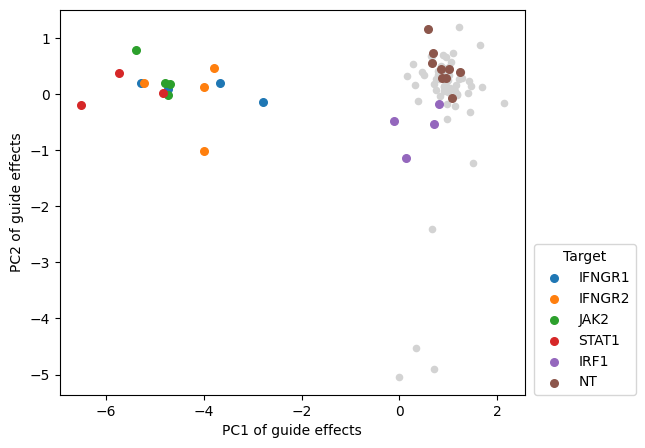

In [9]:
from sklearn.decomposition import PCA

shift = guides.obsm["rna_shift"].to_numpy()
guides.obsm["X_pca_shift"] = PCA(n_components=10, random_state=0).fit_transform(shift)
guides.obsp["shift_correlation"] = np.corrcoef(shift)

highlight = ["IFNGR1", "IFNGR2", "JAK2", "STAT1", "IRF1", "NT"]
fig, ax = plt.subplots(figsize=(6, 5))
pcs = guides.obsm["X_pca_shift"]
ax.scatter(pcs[:, 0], pcs[:, 1], color="lightgrey", s=20)
for gene, color in zip(highlight, sns.color_palette("tab10", len(highlight)), strict=True):
    member = (target == gene).to_numpy()
    ax.scatter(pcs[member, 0], pcs[member, 1], color=color, s=30, label=gene)
ax.set_xlabel("PC1 of guide effects")
ax.set_ylabel("PC2 of guide effects")
ax.legend(loc=(1.02, 0), title="Target")
plt.show()

The guides against the core of interferon gamma signaling, the receptor subunits IFNGR1 and IFNGR2, the kinase JAK2
and the transcription factor STAT1, form a group far from the non-targeting controls, and IRF1 guides sit between the
two.

## Do guides of the same gene agree?

Every guide can be checked against its siblings, the other guides of its gene. Guides that target the same gene
should correlate more with each other than with guides of other genes.

In [10]:
correlation = guides.obsp["shift_correlation"]
same_gene = target.to_numpy()[:, None] == target.to_numpy()[None, :]
siblings = same_gene & ~np.eye(len(target), dtype=bool)
agreement = pd.DataFrame(
    {
        "gene_target": target.to_numpy(),
        "with_siblings": np.nanmean(np.where(siblings, correlation, np.nan), axis=1),
        "with_other_genes": np.nanmean(np.where(~same_gene, correlation, np.nan), axis=1),
    }
)
agreement.groupby("gene_target").mean().sort_values("with_siblings", ascending=False).round(2).head(10)

,with_siblings,with_other_genes
gene_target,,
JAK2,0.96,0.12
IFNGR1,0.94,0.14
STAT1,0.93,0.13
IFNGR2,0.91,0.14
SMAD4,0.88,0.11
IRF1,0.85,0.17
CUL3,0.80,0.12
STAT2,0.72,0.05
BRD4,0.53,0.09


For the strongest regulators the guides correlate at 0.85 or more with their siblings and only around 0.1 with guides
of other genes, so their effects are reproducible across guides. Guides against weaker regulators such as NFKBIA agree
much less, as expected when the effect is close to the noise.

## Gene level effects across modalities

`get_df` reads variables from any level and any modality and aggregates them to the level we ask for. A prefix
selects the modality, so the PD-L1 transcript CD274 and the PD-L1 surface protein are averaged over all cells of every
target gene in one call.

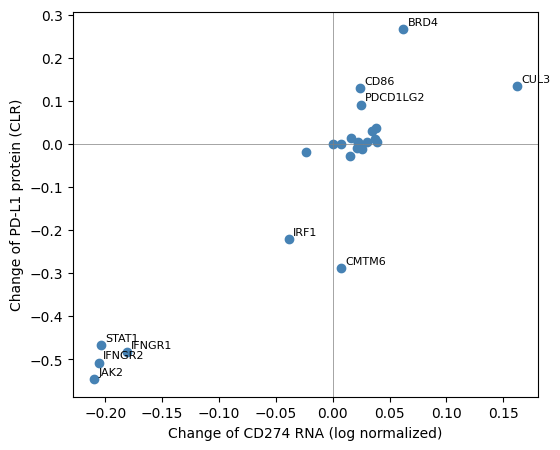

In [11]:
genes = dd.get_df(["rna:CD274", "adt:PDL1", "perturbation"], level="donor")
change = genes[["rna:CD274", "adt:PDL1"]] - genes.loc["NT", ["rna:CD274", "adt:PDL1"]]

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(change["rna:CD274"], change["adt:PDL1"], color="steelblue")
for gene, row in change.iterrows():
    if abs(row["adt:PDL1"]) > 0.08 or abs(row["rna:CD274"]) > 0.05:
        ax.annotate(gene, (row["rna:CD274"], row["adt:PDL1"]), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.axhline(0, color="grey", lw=0.5)
ax.axvline(0, color="grey", lw=0.5)
ax.set_xlabel("Change of CD274 RNA (log normalized)")
ax.set_ylabel("Change of PD-L1 protein (CLR)")
plt.show()

Knockouts along the interferon gamma pathway lower both the transcript and the protein. CMTM6, which stabilizes
PD-L1 at the cell surface, lowers the protein while CD274 RNA stays unchanged, consistent with a post-transcriptional
effect. Knockouts of CUL3 and BRD4 raise PD-L1 instead.

## Back to the cells

The same call at the cell level gives every cell its protein value next to its target gene, which shows how uniform
a perturbation is within a gene.

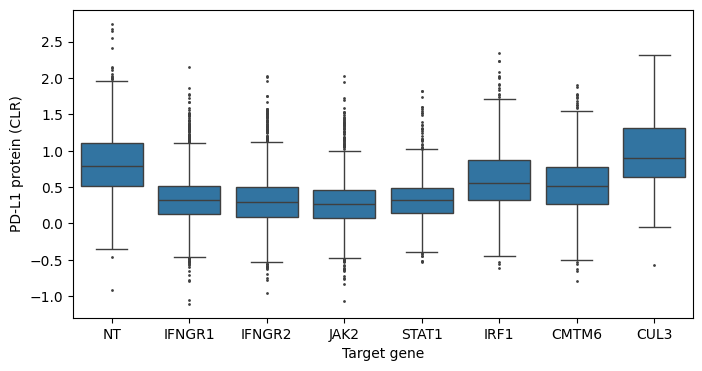

In [12]:
per_cell = dd.get_df(["adt:PDL1", "gene_target"], level="cell")
order = ["NT", "IFNGR1", "IFNGR2", "JAK2", "STAT1", "IRF1", "CMTM6", "CUL3"]
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(
    per_cell[per_cell["gene_target"].isin(order)], x="gene_target", y="adt:PDL1", order=order, ax=ax, fliersize=1
)
ax.set_xlabel("Target gene")
ax.set_ylabel("PD-L1 protein (CLR)")
plt.show()

Within every targeting gene part of the cells keeps PD-L1 at control levels, cells in which the knockout did not take
effect. Methods such as mixscape remove them before effects are estimated.

## Holding out whole perturbations

Models that predict the effect of an unseen perturbation have to be evaluated on genes they never saw in training.
Splits are drawn over the donor level, so all guides and cells of a test gene are held out together. Genes of the
same pathway have nearly identical effects, so a model can still look good by recognizing a pathway it was trained
on. With `groups`, whole groups of genes stay on the same side of the split.

In [13]:
targeting = dd.filter_donors("perturbation == 'Perturbed'")
ifng_pathway = ["IFNGR1", "IFNGR2", "JAK2", "STAT1", "IRF1"]
targeting.D["module"] = np.where(targeting.D.index.isin(ifng_pathway), "IFNG pathway", targeting.D.index)

train, test = targeting.train_test_split(0.2, groups="module", random_state=0)
print("test genes:", list(test.D.index))
print("guides shared between train and test:", set(train.S.index) & set(test.S.index))
print("IFNG pathway genes in train:", sorted(set(ifng_pathway) & set(train.D.index)))
print("IFNG pathway genes in test:", sorted(set(ifng_pathway) & set(test.D.index)))

test genes: ['CUL3', 'MARCH8', 'NFKBIA', 'SMAD4']
guides shared between train and test: set()
IFNG pathway genes in train: ['IFNGR1', 'IFNGR2', 'IRF1', 'JAK2', 'STAT1']
IFNG pathway genes in test: []


## Saving

Genes, guides, the MuData of cells and every matrix aligned to them are written to a single HDF5 file or Zarr store.

In [14]:
dd.write_dd("data/papalexi.dd.zarr")
read_dd("data/papalexi.dd.zarr")

╔═ DonorData(n_donors=24, n_samples=92, n_cells=20,362) ═══════════════════════╗
║ ┏━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓ ║
║ ┃                        ┃ S (samples, 2..9 per   ┃ C (cells, 50..579 per  ┃ ║
║ ┃ D (donors)             ┃ donor)                 ┃ sample)                ┃ ║
║ ┡━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩ ║
║ │ DataFrame with 24      │ DataFrame with 92      │ MuData object with     │ ║
║ │ donors × 1 columns     │ samples × 2 columns    │ n_obs × n_vars =       │ ║
║ │                        │                        │ 20,362 × 18,776        │ ║
║ │     columns:           │     columns:           │     mod: 'rna', 'adt', │ ║
║ │ 'perturbation'         │ 'gene_target', 'NT'    │ 'hto', 'gdo'           │ ║
║ │                        │     obsm: 'rna_shift', │     obs: 'MULTI_ID',   │ ║
║ │                        │ 'rna_mean',            │ 'HTO_classification',  │ ║
║ │                        │ 'X_pca_shift'          │ 'guide_ID',            │ ║
║ │                        │                        │ 'gene_target',         │ ║
║ │                        │                        │ 'replicate',           │ ║
║ │                        │                        │ 'S.Score',             │ ║
║ │                        │                        │ 'G2M.Score', 'phase'   │ ║
║ │                        │     obsp:              │     obsm: 'adt',       │ ║
║ │                        │ 'shift_correlation'    │ 'hto', 'rna', 'gdo'    │ ║
║ │                        │                        │     varm: 'hto',       │ ║
║ │                        │                        │ 'adt', 'rna', 'gdo'    │ ║
║ └────────────────────────┴────────────────────────┴────────────────────────┘ ║
╚═ donor_id='gene_target', sample_id='guide_ID' ═══════════════════════════════╝